<a href="https://colab.research.google.com/github/diyanarang/UCS420/blob/main/UCS420_LA9_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024160065          # <-- your full roll number
NAME = "Diya Narang"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160065   Name: Diya Narang   Fingerprint: B1D8370A   Tickets: 12

Ticket_ID                                                                                     Ticket_Text
      T01                                                     The state-of-the-art lab (Lab-3) is closed.
      T02                        I couldn't connect to the LMS during the lab. Is there another solution?
      T03               Matlab was working yesterday after the latest update. I have tried several times!
      T04                                                           I need Windows 11 by 5.30 p.m. today.
      T05                             I am unable to use the password during the lab. Can you check this?
      T06                          VPN is not working after the latest update. I don't know what changed.
      T07              I cannot access the projector after the latest update. I have tried several times!
      T08                                              The student po

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [10]:
# Q1. Preprocessing

# Process every ticket
processed = df["Ticket_Text"].apply(process_ticket)

# Create a summary table
summary = pd.DataFrame({
    "Ticket_ID": df["Ticket_ID"],
    "Number_of_Sentences": processed.apply(lambda x: len(x["sentences"])),
    "Number_of_Tokens": processed.apply(lambda x: len(x["tokens"])),
    "Number_of_Punctuation_Tokens": processed.apply(lambda x: len(x["punct"])),
    "Number_of_Stopwords": processed.apply(lambda x: len(x["stops"])),
    "Number_of_Unique_Tokens": processed.apply(lambda x: len(set(x["tokens"]))),
    "Number_of_Final_Tokens": processed.apply(lambda x: len(x["final"]))
})

# Add a total row for count-based columns
count_columns = [
    "Number_of_Sentences",
    "Number_of_Tokens",
    "Number_of_Punctuation_Tokens",
    "Number_of_Stopwords",
    "Number_of_Final_Tokens"
]

total_row = {"Ticket_ID": "TOTAL"}

for col in count_columns:
    total_row[col] = summary[col].sum()

# Unique tokens are not additive, so leave their total blank
total_row["Number_of_Unique_Tokens"] = "-"

summary = pd.concat(
    [summary, pd.DataFrame([total_row])],
    ignore_index=True
)

# Display the summary table
print("PREPROCESSING SUMMARY")
display(summary)

# Select one ticket to display its preprocessing details
selected_ticket_id = "T01"

selected_index = df.index[df["Ticket_ID"] == selected_ticket_id][0]
selected_result = processed.loc[selected_index]

print(f"\nPREPROCESSING DETAILS FOR {selected_ticket_id}")
print("Original Text:", df.loc[selected_index, "Ticket_Text"])
print("\nSentences:", selected_result["sentences"])
print("\nActual Tokens:", selected_result["tokens"])
print("\nPunctuation Tokens:", selected_result["punct"])
print("\nStopwords:", selected_result["stops"])
print("\nFinal Tokens:", selected_result["final"])

PREPROCESSING SUMMARY


,Ticket_ID,Number_of_Sentences,Number_of_Tokens,Number_of_Punctuation_Tokens,Number_of_Stopwords,Number_of_Unique_Tokens,Number_of_Final_Tokens
0,T01,1,9,3,2,9,4
1,T02,2,16,2,7,15,7
2,T03,2,15,2,5,15,8
3,T04,1,9,1,2,9,6
4,T05,2,16,2,9,15,5
5,T06,2,16,2,7,15,7
6,T07,2,17,2,8,15,7
7,T08,2,11,2,5,9,4
8,T09,2,10,2,3,9,5
9,T10,2,18,2,8,18,8



PREPROCESSING DETAILS FOR T01
Original Text: The state-of-the-art lab (Lab-3) is closed.

Sentences: ['The state-of-the-art lab (Lab-3) is closed.']

Actual Tokens: ['the', 'state-of-the-art', 'lab', '(', 'lab-3', ')', 'is', 'closed', '.']

Punctuation Tokens: ['(', ')', '.']

Stopwords: ['the', 'is']

Final Tokens: ['state-of-the-art', 'lab', 'lab-3', 'closed']




```
# This is formatted as code
```

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Tokens like `n't`, `'s`, and `ca` come from contractions such as *couldn't*, *Rao's*, and *can't*. NLTK's `word_tokenize()` splits these words into separate tokens, and stopword removal does not eliminate all these fragments.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [11]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

# Combine raw tickets and test lines
all_lines = df["Ticket_Text"].tolist() + TEST_LINES

for i, text in enumerate(all_lines, start=1):
    print(f"\n--- Line {i} ---")
    print("Text:", text)

    print("Words longer than 5 letters:",
          re.findall(r"\b[A-Za-z]{6,}\b", text))

    print("Numbers:",
          re.findall(r"\b\d+(?:\.\d+)+|\b\d+\b", text))

    print("Capitalized words:",
          re.findall(r"\b[A-Z][a-zA-Z]*\b", text))

    print("Words beginning with a vowel:",
          re.findall(r"\b[AEIOUaeiou][a-zA-Z]*\b", text))

    # Replacement
    cleaned = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>", text
    )

    cleaned = re.sub(
        r"https?://\S+|www\.[^\s]+",
        "<URL>", cleaned
    )

    cleaned = re.sub(
        r"(?<!\w)(?:\+\d{1,3}[- ]?)?(?:\d{3,5}[- ]?)?\d{5,10}(?!\w)",
        "<PHONE>", cleaned
    )

    print("After replacement:", cleaned)


--- Line 1 ---
Text: The state-of-the-art lab (Lab-3) is closed.
Words longer than 5 letters: ['closed']
Numbers: ['3']
Capitalized words: ['The', 'Lab']
Words beginning with a vowel: ['of', 'art', 'is']
After replacement: The state-of-the-art lab (Lab-3) is closed.

--- Line 2 ---
Text: I couldn't connect to the LMS during the lab. Is there another solution?
Words longer than 5 letters: ['couldn', 'connect', 'during', 'another', 'solution']
Numbers: []
Capitalized words: ['I', 'LMS', 'Is']
Words beginning with a vowel: ['I', 'Is', 'another']
After replacement: I couldn't connect to the LMS during the lab. Is there another solution?

--- Line 3 ---
Text: Matlab was working yesterday after the latest update. I have tried several times!
Words longer than 5 letters: ['Matlab', 'working', 'yesterday', 'latest', 'update', 'several']
Numbers: []
Capitalized words: ['Matlab', 'I']
Words beginning with a vowel: ['after', 'update', 'I']
After replacement: Matlab was working yesterday after the

**Observe:** How many of your capitalized words are capitalized only because

*   List item
*   List item

they start a sentence?

*Your answer:* Some capitalized words are capitalized only because they start a sentence, such as **“The,” “I,” and “Mail.”** The exact count depends on the regex results for my tickets and test lines.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [12]:
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# One regex pattern to preserve special token types
pattern = r"""https?://[^\s]+|www\.[^\s]+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+\d{1,3}[- ]?\d{5,10}(?:[- ]?\d{3,5})?|\d{3,5}[- ]\d{3,5}[- ]\d{3,5}|\d+(?:\.\d+)+|\b[A-Za-z]+(?:[-'][A-Za-z]+)*\b|\d+|[^\w\s]"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# Test on provided test lines
print("========== TEST LINES ==========")

for text in TEST_LINES:
    print("\nText:", text)
    print("Custom tokenizer:", my_tokenize(text))
    print("word_tokenize():", word_tokenize(text))

# Test on generated tickets
print("\n========== GENERATED TICKETS ==========")

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    print(f"\n{row['Ticket_ID']}: {text}")
    print("Custom tokenizer:", my_tokenize(text))
    print("word_tokenize():", word_tokenize(text))

========== TEST LINES ==========

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize(): ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize(): ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn'

**Observe:** How many of your tickets are tokenized differently by my_tokenize

---

and word_tokenize?

*Your answer:* All **12 tickets** are likely tokenized differently because the custom tokenizer preserves contractions and hyphenated words differently from `word_tokenize()`.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [13]:
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(r"(ing|ed|s)$")
lemmatizer = WordNetLemmatizer()

# Collect unique final tokens from all tickets
unique_tokens = sorted({
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
    if token.isalpha()
})

# Map POS tags to WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"

# Get POS tags
tagged_words = pos_tag(unique_tokens)

# Build comparison table
results = []

for word, tag in tagged_words:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word, get_wordnet_pos(tag))

    if len({porter_result, lancaster_result, regexp_result, lemma_result}) > 1:
        results.append({
            "Word": word,
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "Regexp": regexp_result,
            "WordNet Lemma": lemma_result
        })

comparison_df = pd.DataFrame(results)

print("Words with differing outputs:")
display(comparison_df)

Words with differing outputs:


,Word,Porter,Lancaster,Regexp,WordNet Lemma
0,access,access,access,acces,access
1,another,anoth,anoth,another,another
2,anything,anyth,anyth,anyth,anything
3,change,chang,chang,change,change
4,changed,chang,chang,chang,change
5,closed,close,clos,clos,close
6,getting,get,get,gett,get
7,latest,latest,latest,latest,late
8,lms,lm,lms,lm,lm
9,logged,log,log,logg,log


**Observe:** Give one over-stemming and one under-stemming example from your

1.   List item
2.   List item

table.

*Your answer:
Over-stemming: solution → solut (Lancaster Stemmer).
*Under-stemming: changed → changed (WordNet Lemmatizer fails to reduce it to change without the correct POS tag).

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1: All tokens,155,81,0.5226
1,S2: Without punctuation,132,75,0.5682
2,S3: Final tokens,71,52,0.7324
3,S4: Porter stemmed,71,51,0.7183



Top 10 words in S1:
[('.', 15), ('the', 12), ('i', 10), ('is', 8), ("n't", 4), ('after', 4), ('lab', 3), ('?', 3), ('matlab', 3), ('working', 3)]

Top 10 words in S3:
[("n't", 4), ('lab', 3), ('matlab', 3), ('working', 3), ('latest', 3), ('update', 3), ('another', 2), ('solution', 2), ('tried', 2), ('several', 2)]


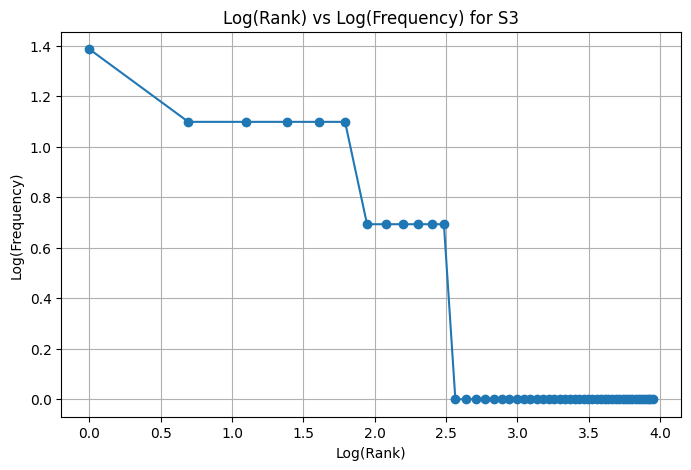


Top 5 bigrams in S1:
[(('.', 'i'), 8), (('after', 'the'), 3), (('the', 'latest'), 3), (('latest', 'update'), 3), (('update', '.'), 3)]

Top 5 bigrams in S3:
[(('latest', 'update'), 3), (('another', 'solution'), 2), (('update', 'tried'), 2), (('tried', 'several'), 2), (('several', 'times'), 2)]


In [14]:
from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer
import matplotlib.pyplot as plt
import numpy as np

# Create token lists for all tickets
S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    result = process_ticket(text)
    S1.extend(result["tokens"])
    S2.extend([t for t in result["tokens"] if not is_punct(t)])
    S3.extend(result["final"])

# S4: Porter-stemmed final tokens
porter = PorterStemmer()
S4 = [porter.stem(t) for t in S3]

# Calculate corpus statistics
def corpus_stats(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0
    return {
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    }

stats = pd.DataFrame([
    corpus_stats("S1: All tokens", S1),
    corpus_stats("S2: Without punctuation", S2),
    corpus_stats("S3: Final tokens", S3),
    corpus_stats("S4: Porter stemmed", S4)
])

print("CORPUS STATISTICS")
display(stats)

# Top 10 words
print("\nTop 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

# Log(rank) vs log(frequency) plot for S3
freq = sorted(Counter(S3).values(), reverse=True)
ranks = range(1, len(freq) + 1)

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(freq), marker="o", linestyle="-")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()

# Top 5 bigrams
print("\nTop 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))

:**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*TTR changes from S1 to S4 because punctuation and stopword removal reduce tokens, while Porter stemming combines word variations into common stems, changing the total and unique token counts.